<a href="https://colab.research.google.com/github/APenn215/Research-Methods-/blob/main/Telco_Customer_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Introduction**
The purpose of this project is to explore the Telco Customer Churn dataset and understand how customer characteristics and service-related factors are associated with customer churn. Customer churn occurs when customers stop using a company's services. By analyzing this dataset, we can identify patterns that may help telecommunications companies better understand customer behavior.
This project focuses on improving data quality through data cleaning and preprocessing techniques, including handling missing values, detecting outliers, converting data types, encoding categorical variables, and feature scaling. Exploratory data analysis  will also be performed to examine relationships between customer demographics, service usage, monthly charges, and churn.

In [47]:
# import liberies

# Import libraries for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# **3. Data Cleaning and Preprocessing**

In [ ]:
# Load Dataset

from google.colab import files

uploaded = "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(uploaded)
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 7043
Number of columns: 21


In [ ]:
#  general information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# numerical variables

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

print("Numerical Variables:")
print(numerical_cols.tolist())

# categorical variables

categorical_cols = df.select_dtypes(include=['object', 'category']).columns

print("\nCategorical Variables:")
print(categorical_cols.tolist())

Numerical Variables:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical Variables:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [ ]:
# descriptive statistics for numerical variables

df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
#  missing values in each column

df.isnull().sum()


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


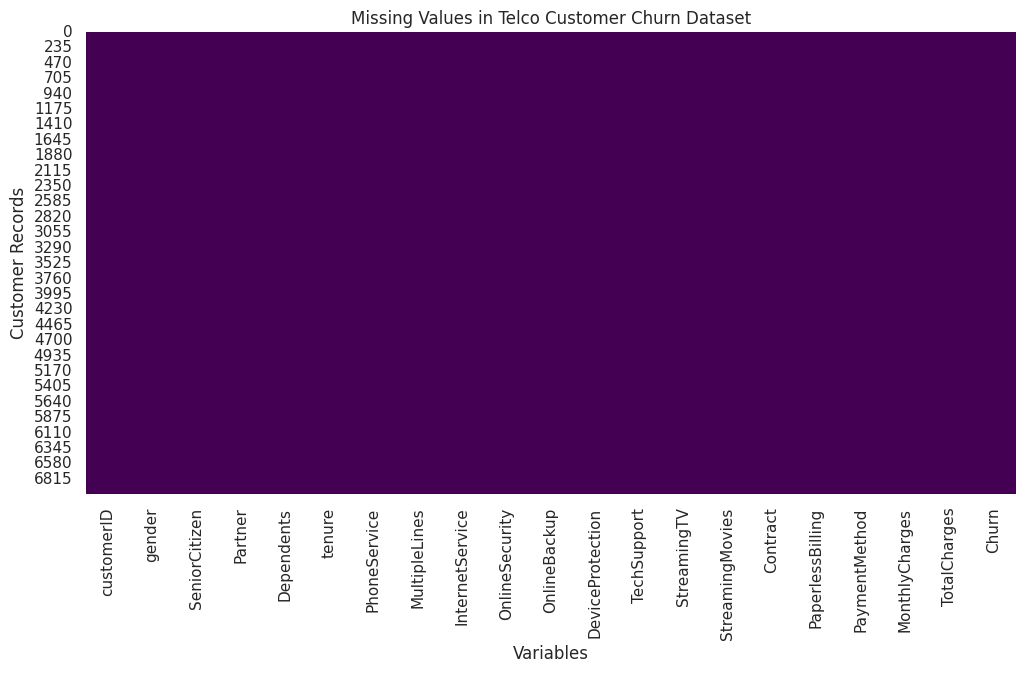

In [ ]:
# Heatmap

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap='viridis'
)

plt.title('Missing Values in Telco Customer Churn Dataset')
plt.xlabel('Variables')
plt.ylabel('Customer Records')

plt.show()

In [ ]:
# Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check for missing values
df.isnull().sum()

# Remove rows with missing TotalCharges
df = df.dropna(subset=['TotalCharges'])

# Confirm missing values were removed
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
# Check dataset size after removing missing values

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (7043, 21)


In [ ]:
# Confirm that no missing values remain

print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


### **Handling Missing Values**
Missing values were identified using the isnull() function in pandas. During the initial assessment, the dataset appeared to contain no missing values. However, further examination revealed that the TotalCharges column was stored as an object rather than a numerical variable. After converting the column to a numerical data type, 11 missing values were identified, representing approximately 0.16% of the dataset.
A heatmap was created to visualize the missing data patterns and identify which variables contained incomplete information. Since the missing values represented a very small portion of the dataset, the affected records were removed rather than replaced through imputation. This approach was selected to avoid introducing estimated values into the analysis while preserving most of the original dataset.
After removing the missing records, the dataset contained 7,032 customer records and 21 variables. A final missing-value check confirmed that no missing values remained.

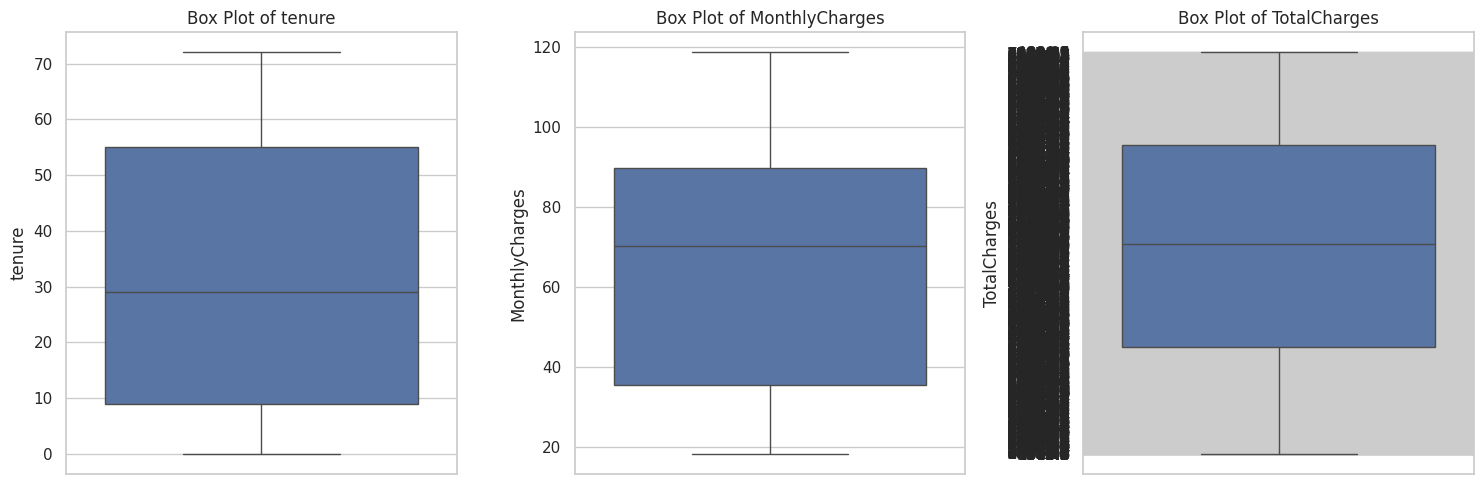

In [ ]:
# Select numerical variables

numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Create box plots

plt.figure(figsize=(15, 5))

for i, col in enumerate(numerical_cols):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()

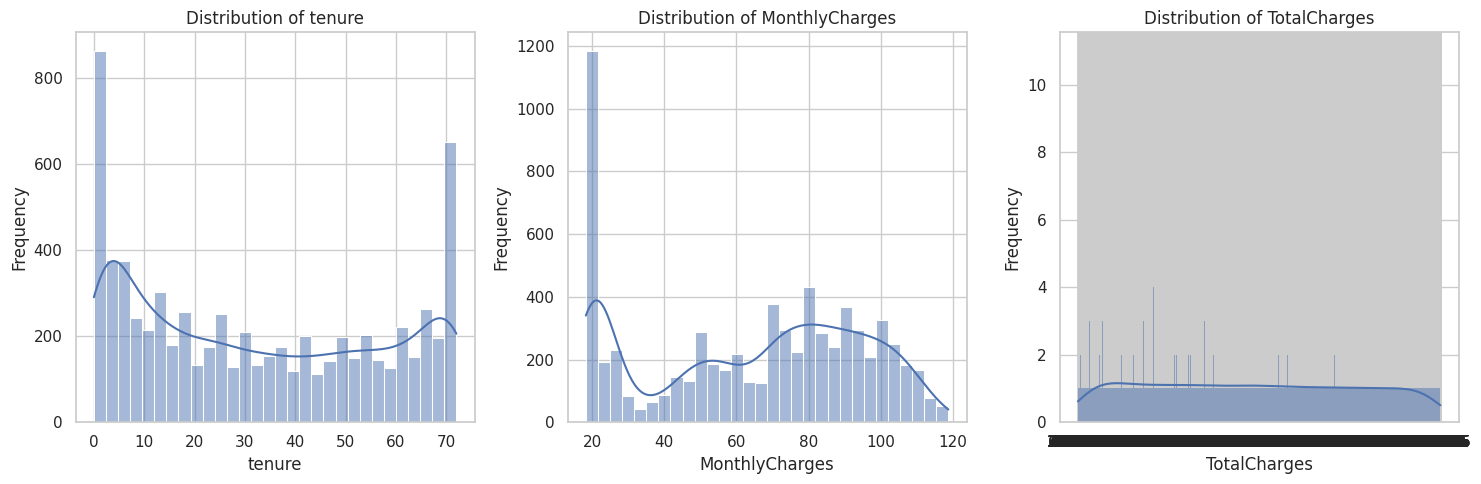

In [ ]:
# Create histograms for numerical variables

plt.figure(figsize=(15, 5))

for i, col in enumerate(numerical_cols):
    plt.subplot(1, 3, i + 1)
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:
# Detect outliers using the IQR method

# Convert 'TotalCharges' to numeric, coercing errors to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# Drop rows where 'TotalCharges' became NaN after coercion
df.dropna(subset=['TotalCharges'], inplace=True)

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nVariable: {col}")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")
    print(f"Number of Outliers: {len(outliers)}")


Variable: tenure
Lower Bound: -60.00
Upper Bound: 124.00
Number of Outliers: 0

Variable: MonthlyCharges
Lower Bound: -45.82
Upper Bound: 171.27
Number of Outliers: 0

Variable: TotalCharges
Lower Bound: -4688.48
Upper Bound: 8884.67
Number of Outliers: 0


In [ ]:
# Check minimum and maximum values

df[numerical_cols].agg(['min', 'max'])

,tenure,MonthlyCharges,TotalCharges
min,1,18.25,18.8
max,72,118.75,8684.8


In [ ]:
# Retain valid observations after outlier assessment

df_cleaned = df.copy()

print("Dataset shape after outlier assessment:", df_cleaned.shape)

Dataset shape after outlier assessment: (7032, 21)


### **Outlier Detection and Treatment**
Outliers were examined in the numerical variables tenure, MonthlyCharges, and TotalCharges using box plots, histograms, and the Interquartile Range (IQR) method. The IQR method was used to calculate the lower and upper boundaries for each variable and identify values that fell outside those ranges.
The results showed that no outliers were detected in any of the three numerical variables. All observations fell within their calculated IQR boundaries, suggesting that the numerical values were within the expected statistical ranges for this dataset. Since no outliers were identified, no observations were removed or transformed. All 7,032 customer records were retained for further analysis.

In [ ]:
# Check the data types of all columns

df_cleaned.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
# Identify categorical variables

categorical_cols = df_cleaned.select_dtypes(
    include=['object']
).columns.tolist()

# Exclude customerID because it is a unique identifier

categorical_cols.remove('customerID')

# Include SeniorCitizen because 0 and 1 represent categories

categorical_cols.append('SeniorCitizen')

# Convert categorical variables

df_cleaned[categorical_cols] = df_cleaned[
    categorical_cols
].astype('category')

# Check updated data types

df_cleaned.dtypes

,0
customerID,object
gender,category
SeniorCitizen,category
Partner,category
Dependents,category
tenure,int64
PhoneService,category
MultipleLines,category
InternetService,category
OnlineSecurity,category


In [ ]:
# Confirm numerical variables are correctly formatted

df_cleaned['tenure'] = df_cleaned['tenure'].astype('int64')

df_cleaned['MonthlyCharges'] = df_cleaned[
    'MonthlyCharges'
].astype('float64')

df_cleaned['TotalCharges'] = df_cleaned[
    'TotalCharges'
].astype('float64')

# Display updated numerical data types

df_cleaned[
    ['tenure', 'MonthlyCharges', 'TotalCharges']
].dtypes

,0
tenure,int64
MonthlyCharges,float64
TotalCharges,float64


In [ ]:
# Verify all data types after conversion

df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7032 non-null   object  
 1   gender            7032 non-null   category
 2   SeniorCitizen     7032 non-null   category
 3   Partner           7032 non-null   category
 4   Dependents        7032 non-null   category
 5   tenure            7032 non-null   int64   
 6   PhoneService      7032 non-null   category
 7   MultipleLines     7032 non-null   category
 8   InternetService   7032 non-null   category
 9   OnlineSecurity    7032 non-null   category
 10  OnlineBackup      7032 non-null   category
 11  DeviceProtection  7032 non-null   category
 12  TechSupport       7032 non-null   category
 13  StreamingTV       7032 non-null   category
 14  StreamingMovies   7032 non-null   category
 15  Contract          7032 non-null   category
 16  PaperlessBilling  7032 non-nu

# **Data Type Conversion**
Data types were examined to ensure that each variable was stored in an appropriate format. The TotalCharges column was previously converted from an object to a numerical variable during the missing-value assessment. The numerical variables tenure, MonthlyCharges, and TotalCharges were confirmed as integer or float data types.
Categorical variables, including contract type, internet service, payment method, and churn status, were converted to the category data type. Although SeniorCitizen was originally stored as an integer, it was also converted to a categorical variable because its values represent two groups rather than numerical measurements. The customerID column was excluded from categorical conversion because it serves as a unique customer identifier.


In [ ]:
# Identify categorical variables

categorical_cols = df_cleaned.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Categorical Variables:")
print(categorical_cols)

Categorical Variables:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [ ]:
# Create a copy of the cleaned dataset

df_encoded = df_cleaned.copy()

# Encode the target variable

df_encoded['Churn'] = (
    df_encoded['Churn']
    .astype(str)
    .map({'No': 0, 'Yes': 1})
)

# Check the results

df_encoded['Churn'].value_counts()

,count
Churn,
0,5163
1,1869


In [ ]:
# Remove customerID from the encoded dataset

df_encoded = df_encoded.drop(columns=['customerID'], errors='ignore')

In [ ]:
# Identify categorical predictors

categorical_features = df_encoded.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Apply one-hot encoding

df_encoded = pd.get_dummies(
    df_encoded,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

# Display the first five rows

df_encoded.head()

,tenure,MonthlyCharges,TotalCharges,Churn,customerID_0003-MKNFE,customerID_0004-TLHLJ,customerID_0011-IGKFF,customerID_0013-EXCHZ,customerID_0013-MHZWF,customerID_0013-SMEOE,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,29.85,29.85,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
1,34,56.95,1889.50,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,2,53.85,108.15,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
3,45,42.30,1840.75,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
4,2,70.70,151.65,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0


In [ ]:
# Check the dataset shape after encoding

print("Original dataset shape:", df_cleaned.shape)

print("Encoded dataset shape:", df_encoded.shape)

Original dataset shape: (7032, 21)
Encoded dataset shape: (7032, 7062)


In [ ]:
# Check for missing values after encoding

print(
    "Missing values after encoding:",
    df_encoded.isnull().sum().sum()
)

Missing values after encoding: 0


### **Encoding Categorical Variables**
Categorical variables were identified and converted into numerical representations to prepare the dataset for machine learning. The Churn variable was encoded as a binary outcome, where 0 represents customers who remained with the company and 1 represents customers who left.
One-hot encoding was applied to the remaining categorical variables, including contract type, internet service, and payment method. The drop_first=True parameter was used to remove one category from each variable and reduce the risk of perfect multicollinearity, also known as the dummy variable trap, in linear models with an intercept.
The customerID column was excluded from encoding because it serves as a unique identifier rather than a meaningful predictor of customer churn. After encoding, the dataset contained numerical variables suitable for further preprocessing and machine learning analysis.

In [ ]:
# Import StandardScaler

from sklearn.preprocessing import StandardScaler

In [ ]:
# Select numerical features for scaling

numerical_features = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

# Create a copy of the encoded dataset

df_scaled = df_encoded.copy()

In [ ]:
# Initialize StandardScaler

scaler = StandardScaler()

# Standardize numerical features

df_scaled[numerical_features] = scaler.fit_transform(
    df_scaled[numerical_features]
)

# Display the first five rows

df_scaled[numerical_features].head()

,tenure,MonthlyCharges,TotalCharges
0,-1.280248,-1.161694,-0.994194
1,0.064303,-0.260878,-0.173740
2,-1.239504,-0.363923,-0.959649
3,0.512486,-0.747850,-0.195248
4,-1.239504,0.196178,-0.940457


In [ ]:
# Check mean and standard deviation after scaling

df_scaled[numerical_features].agg(['mean', 'std'])

,tenure,MonthlyCharges,TotalCharges
mean,-1.126643e-16,6.062651e-17,-1.119064e-16
std,1.000071e+00,1.000071e+00,1.000071e+00


In [ ]:
# Compare original and scaled numerical features

print("Original Data:")
display(df_encoded[numerical_features].head())

print("Scaled Data:")
display(df_scaled[numerical_features].head())

Original Data:


,tenure,MonthlyCharges,TotalCharges
0,1,29.85,29.85
1,34,56.95,1889.50
2,2,53.85,108.15
3,45,42.30,1840.75
4,2,70.70,151.65


Scaled Data:


,tenure,MonthlyCharges,TotalCharges
0,-1.280248,-1.161694,-0.994194
1,0.064303,-0.260878,-0.173740
2,-1.239504,-0.363923,-0.959649
3,0.512486,-0.747850,-0.195248
4,-1.239504,0.196178,-0.940457


### **Feature Scaling**

Feature scaling was performed to ensure that numerical variables were represented on a comparable scale. The Telco Customer Churn dataset contains numerical features with different ranges, particularly tenure, MonthlyCharges, and TotalCharges. These differences can affect machine learning algorithms that are sensitive to feature magnitude, such as logistic regression with regularization and K-nearest neighbors.
Standardization was selected because it transforms numerical variables to have a mean of approximately zero and a standard deviation of one while preserving their relative differences. The StandardScaler function from scikit-learn was applied to the three numerical features. Binary categorical variables and the target variable, Churn, were excluded from scaling.
After standardization, the means and standard deviations were examined to confirm that the transformation was successful. The scaled dataset was saved separately to preserve the original numerical values for exploratory data analysis.



# **4. Exploratory Data Analysis (EDA)**

### 4A: Descriptive Statistics

In [ ]:
# Select numerical variables

numerical_cols = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

# Calculate descriptive statistics

descriptive_stats = pd.DataFrame({
    'Mean': df_cleaned[numerical_cols].mean(),
    'Median': df_cleaned[numerical_cols].median(),
    'Mode': df_cleaned[numerical_cols].mode().iloc[0],
    'Variance': df_cleaned[numerical_cols].var(),
    'Standard Deviation': df_cleaned[numerical_cols].std()
})

# Round results to two decimal places

descriptive_stats = descriptive_stats.round(2)

# Display results

descriptive_stats

,Mean,Median,Mode,Variance,Standard Deviation
tenure,32.42,29.00,1.00,602.47,24.55
MonthlyCharges,64.80,70.35,20.05,905.17,30.09
TotalCharges,2283.30,1397.48,20.20,5138252.41,2266.77


**Interpretation of Descriptive Statistics**

The descriptive statistics provide insight into customer tenure and billing patterns. Customers had an average tenure of 32.42 months, with a median of 29 months and a mode of 1 month, indicating that one-month tenure was the most frequently occurring value. Monthly charges averaged 64.80, with a median of 70.35 and a standard deviation of 30.09, showing that monthly payments varied considerably among customers. Total charges had a mean of 2,283.30 and a median of 1,397.48, suggesting a right-skewed distribution in which higher total charges pull the average upward. The large standard deviation of 2,266.77 also indicates substantial variation in total customer spending.

### **4B: Data Visualization**

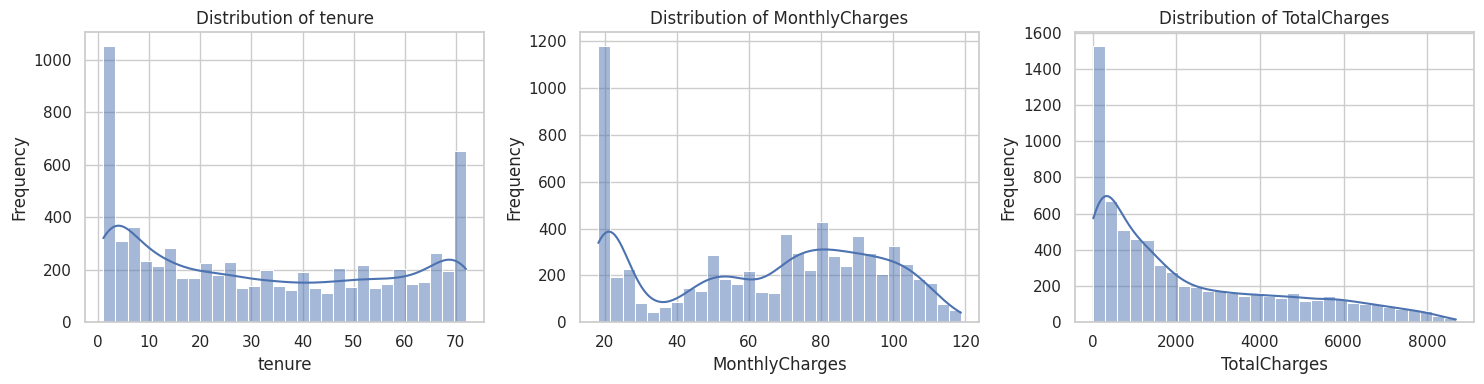

In [ ]:
# Univariate Analysis: Histograms and Density Plots

numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(numerical_cols):
    sns.histplot(
        df_cleaned[col],
        kde=True,
        bins=30,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

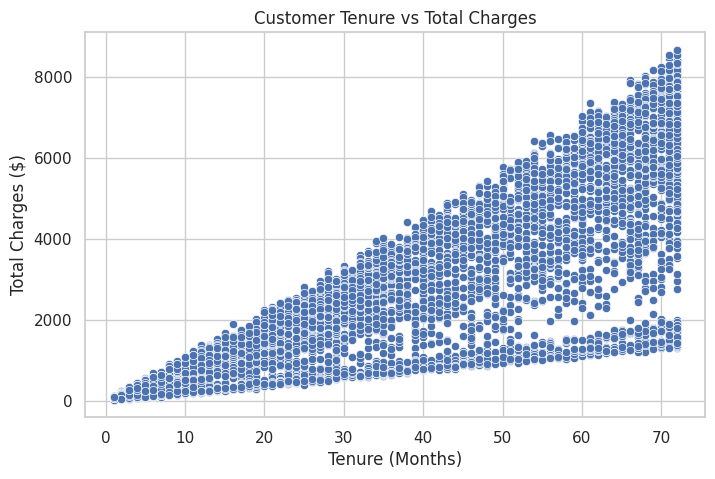

In [48]:
# Scatter Plot: Tenure vs Total Charges

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_cleaned,
    x='tenure',
    y='TotalCharges'
)

plt.title('Customer Tenure vs Total Charges')
plt.xlabel('Tenure (Months)')
plt.ylabel('Total Charges ($)')

plt.show()

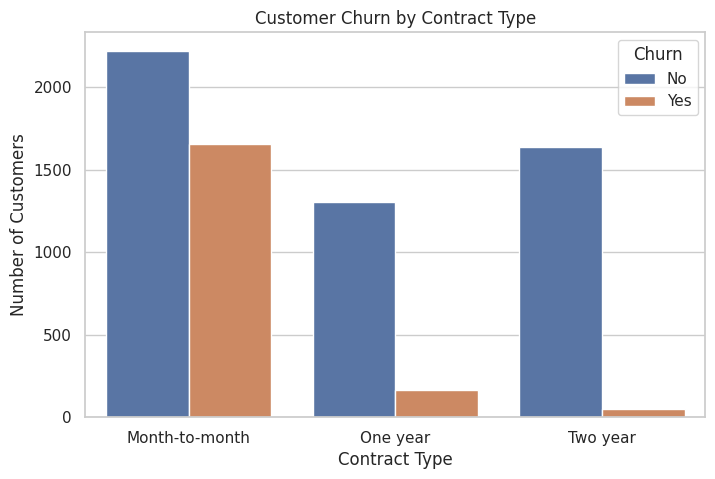

In [ ]:
# Bar Chart: Customer Churn by Contract Type

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_cleaned,
    x='Contract',
    hue='Churn'
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')

plt.show()

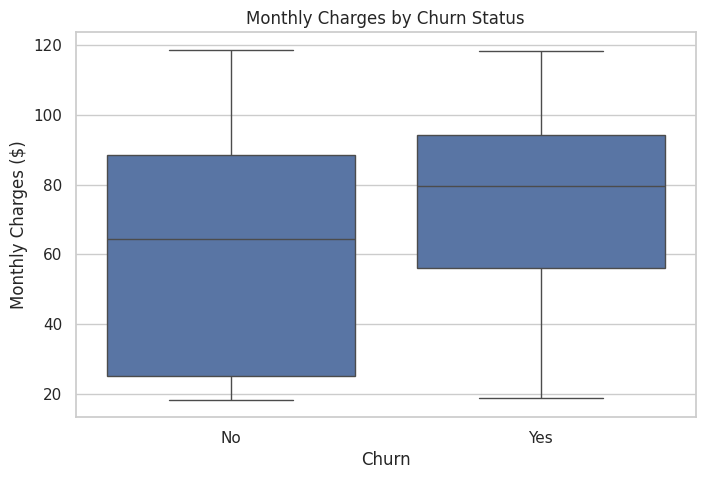

In [ ]:
# Box Plot: Monthly Charges by Churn Status

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_cleaned,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges ($)')

plt.show()

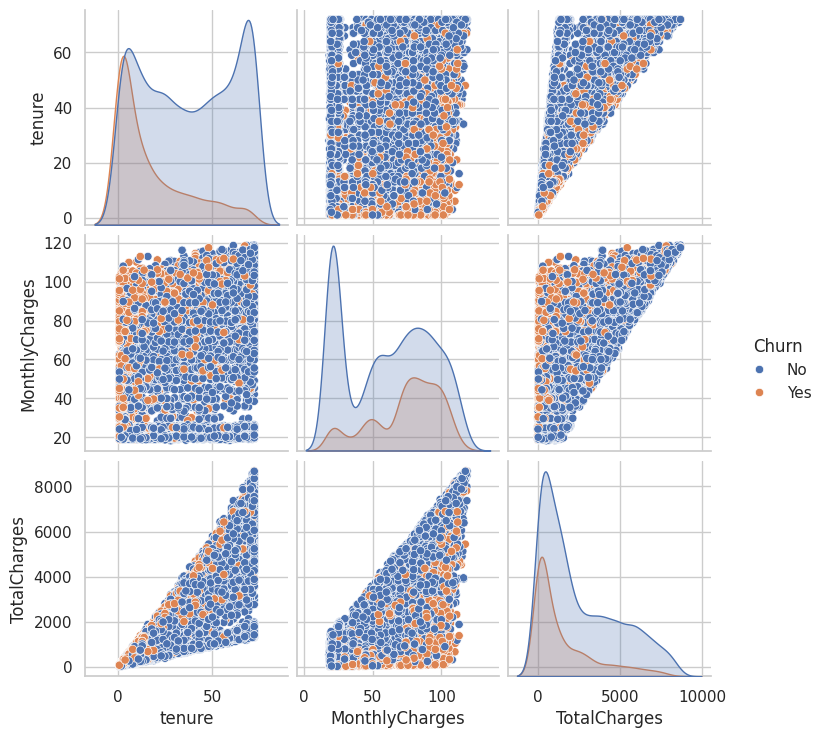

In [ ]:
# Multivariate Analysis: Pair Plot

sns.pairplot(
    df_cleaned,
    vars=['tenure', 'MonthlyCharges', 'TotalCharges'],
    hue='Churn'
)

plt.show()

The visualizations suggest that customer tenure, monthly charges, and contract type are important factors associated with customer churn. Customers with shorter tenure, higher monthly charges, and month-to-month contracts appear more frequently among those who left the company. These findings suggest that telecommunications companies could investigate pricing and early customer retention strategies to better understand and potentially reduce churn.

# 4C.**Correlation Analysis**

In [ ]:
# Calculate Pearson correlations

numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

correlation_matrix = df_cleaned[numerical_cols].corr(method='pearson')

correlation_matrix.round(2)

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


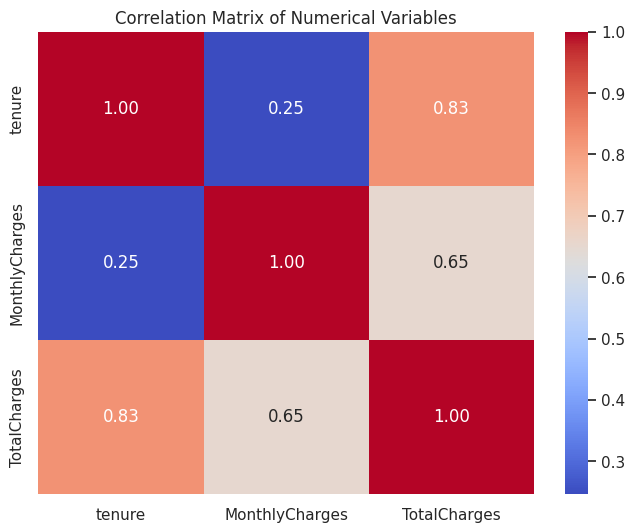

In [ ]:
# Create correlation heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Matrix of Numerical Variables')
plt.show()

**Correlation Analysis Interpretation**

The correlation analysis showed a strong positive relationship between tenure and TotalCharges (0.83), meaning customers who stay with the company longer generally have higher total charges. There was also a moderate positive relationship between MonthlyCharges and TotalCharges (0.65). The relationship between tenure and MonthlyCharges was weaker, with a correlation of 0.25. No negative correlations were found among these numerical variables.

**Findings**

The analysis identified several patterns in the Telco Customer Churn dataset. Customers with month-to-month contracts showed more churn cases than customers with one-year or two-year contracts. Customers who churned also tended to have higher monthly charges and shorter tenure. In addition, tenure had a strong positive correlation with total charges (0.83), showing that customers who remained with the company longer generally accumulated higher total charges.

**Business Implications**

These findings suggest that contract type, monthly charges, and customer tenure may be important factors to consider when examining customer churn. The company could pay particular attention to newer customers, customers with higher monthly bills, and those with month-to-month contracts when developing customer retention strategies. Understanding these patterns could help the company identify groups experiencing higher churn and investigate ways to improve customer retention.